Encrypting image with shape:  (512, 512, 3)


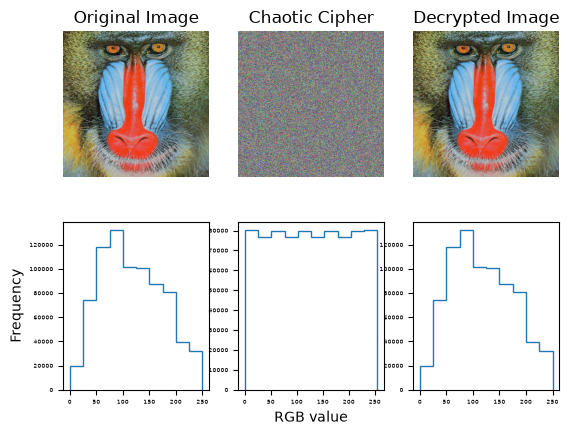

'\nkorrelation\ngrannkorrelation\nuaci och npcr\nentropi\nhistogram\n'

In [2]:
%load_ext autoreload
%autoreload 2
import ImageToMatrix as itm
import matplotlib.pyplot as plt
import numpy as np
from matt_enkel import entropi, korrelation, grannkorrelation
from PIL import Image

'''
korrelation
grannkorrelation
uaci och npcr
entropi
histogram
'''

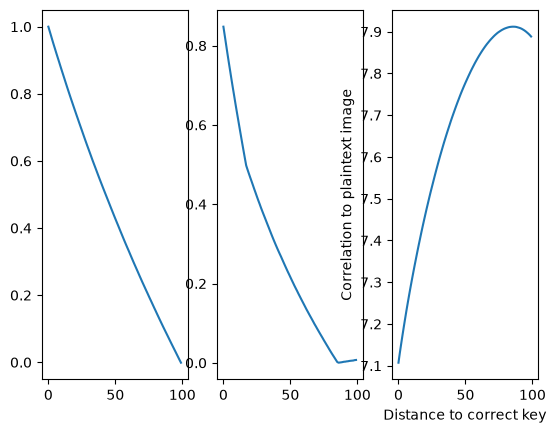

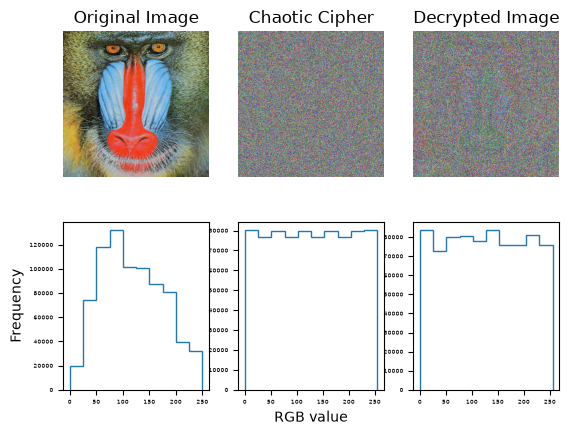

In [8]:

# Samma bilder som i ImageToMatrix.py
iterations = 100
finetune = 5  # Välj från 1-5, högre värde ger sämre granularitet men större förändring
original = itm.matrix
krypterad = itm.chaoticencryptedArray.reshape(original.shape)
ratt_nycklar = itm.chaotickeys.T
nearMissnycklar = np.empty(
    (iterations + 1, *ratt_nycklar.shape), dtype=ratt_nycklar.dtype
)
tmpnyckel = ratt_nycklar.copy()

for i in range(iterations):
    nearMissnycklar[i] = tmpnyckel.copy()
    start = i * 512 * finetune
    end = start + 512 * finetune  # change one row of pixels at a time
    tmpnyckel[start:end, :] ^= 100 % 256
# for i in range(iterations):
#     nearMissnycklar[i] = tmpnyckel.copy()
#     tmpnyckel[i, :] ^= 120 % 256  # Mindre nogrann större förändring

# --- Dekryptering med rätt nycklar------------------------------------------------------------
# desubstituerad = np.bitwise_xor(krypterad.reshape(-1, 3), ratt_nycklar).reshape(
#     original.shape
# )
desubstituerad = itm.inverseLorenzDiffuse(krypterad, ratt_nycklar)
dekrypterad = itm.InverseArnoldCatMapTransform(desubstituerad, 10, 1, 1)
# print(
#      f"Korrelation orig/orig:  {korrelation(original, original):.4f}"
#      f"  Entropi originalbild:   {entropi(original):.4f}"
# )

# # --- Dekryptering med Near-Miss keys ------------------------------------------------------------
nyckelKedja = np.empty((iterations, *original.shape), dtype = np.uint8)
korrarr = np.arange(iterations, dtype=float)
entropiarr = np.arange(iterations, dtype=float)
grannkorrarr = np.arange(iterations, dtype=float)
for i in range(iterations):
    # desubstituerad = np.bitwise_xor(
    #     krypterad.reshape(-1, 3), nearMissnycklar[i]
    # ).reshape(original.shape)
    desubstituerad = itm.inverseLorenzDiffuse(krypterad, nearMissnycklar[i])
    dekrypterad = itm.InverseArnoldCatMapTransform(desubstituerad, 10, 1, 1)
    nyckelKedja[i] = dekrypterad
    korrarr[i] = korrelation(original, dekrypterad)
    entropiarr[i] = entropi(dekrypterad)
    grannkorrarr[i] = grannkorrelation(dekrypterad).get('vertikalt')

    grannkorrelation(dekrypterad)

    # print(
    #     f"Korrelation orig/dekrypterad:  {korrelation(original, dekrypterad):.4f}"
    #     f"  Entropi enkrypteringbild:   {entropi(krypterad):.4f}"
    # )

plt.subplot(1,3,1)
plt.plot(np.arange(iterations), korrarr)

plt.subplot(1,3,2)
plt.plot(np.arange(iterations), grannkorrarr)

plt.subplot(1,3,3)
plt.plot(np.arange(iterations), entropiarr)
plt.xlabel("Distance to correct key")
plt.ylabel("Correlation to plaintext image")
plt.show()
itm.plotImages(original, krypterad, nyckelKedja[-1])


Original shape: (512, 512, 3)
Key shape: (3, 262144)


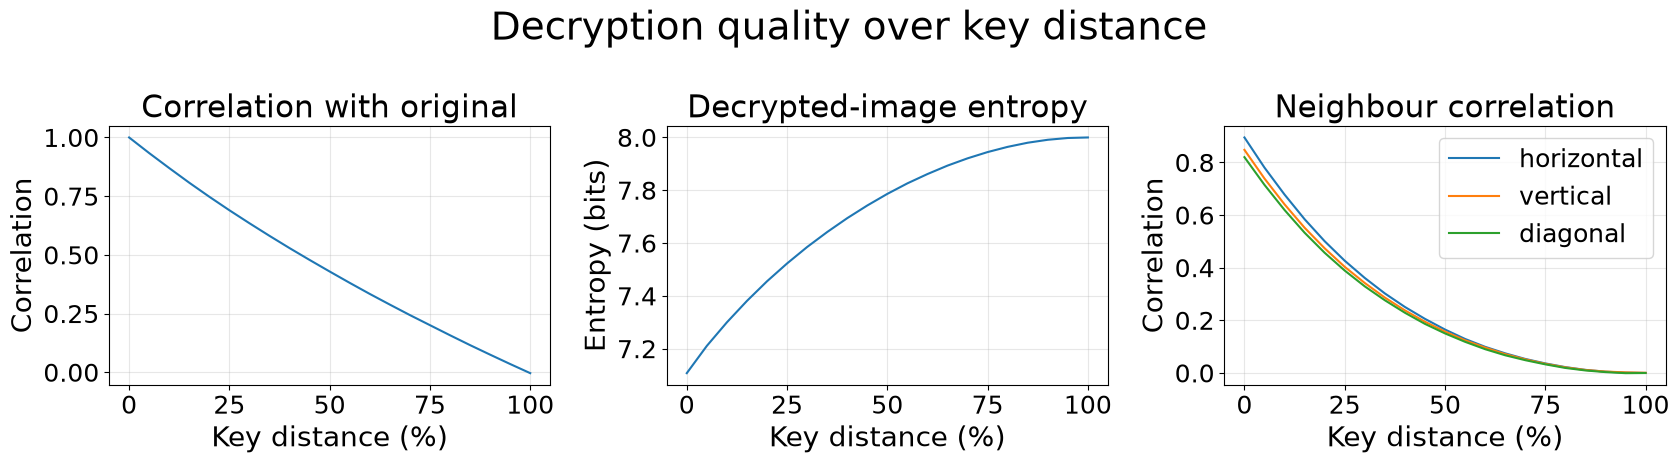

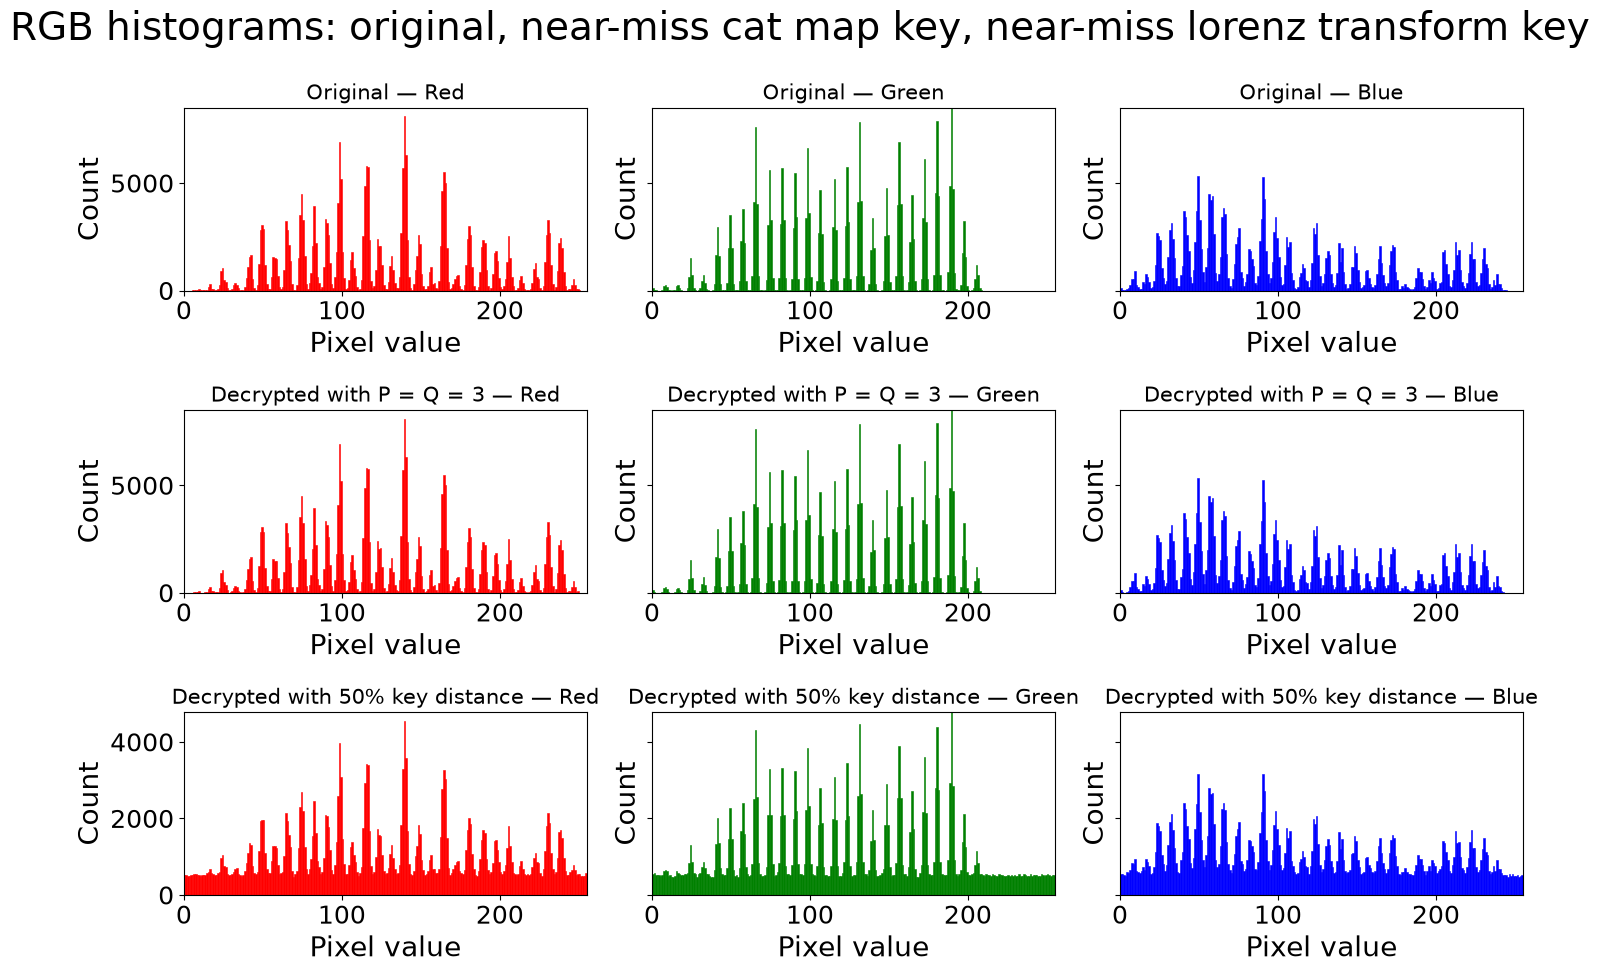

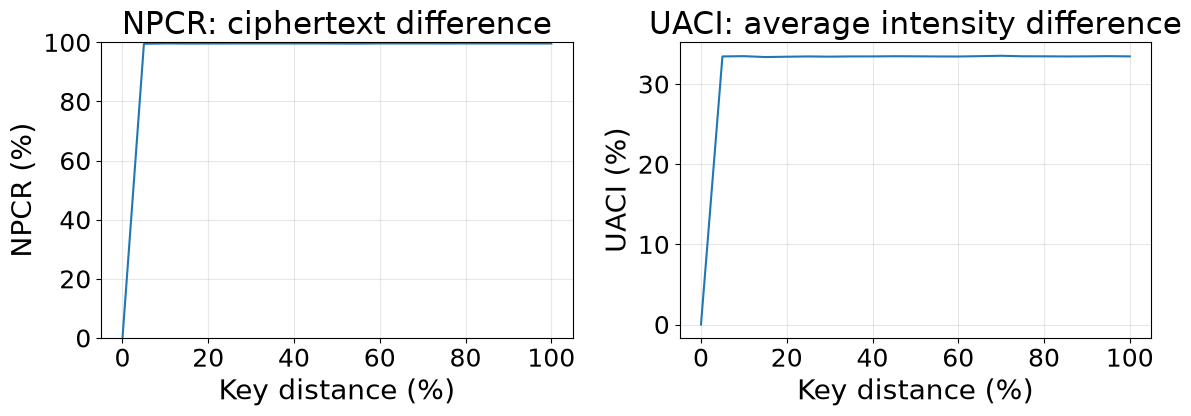

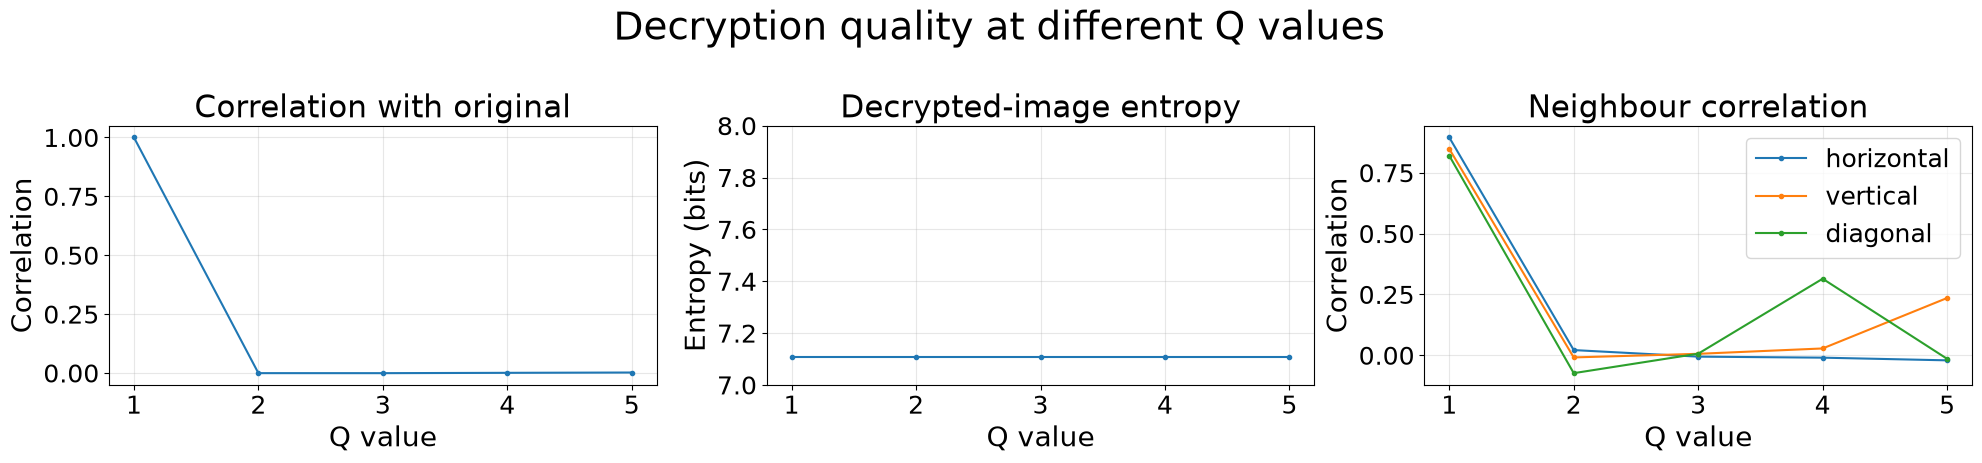

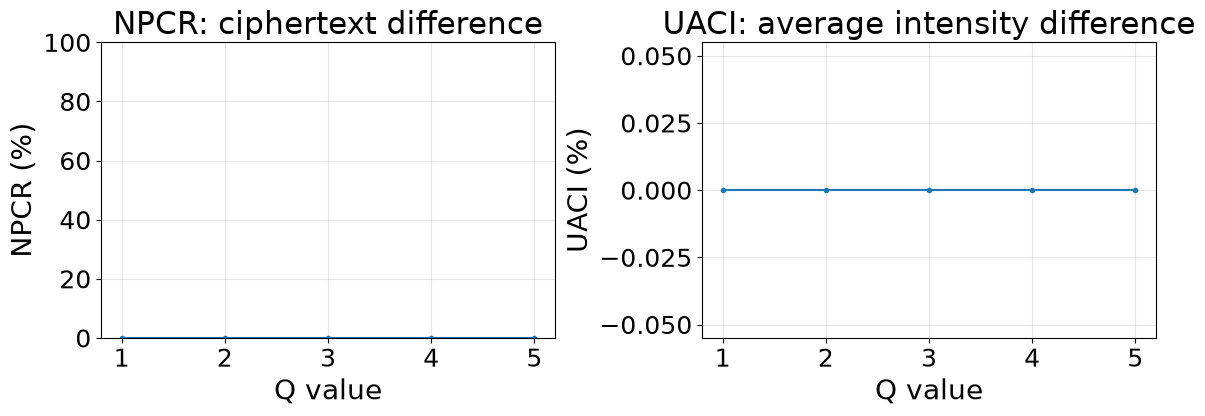

In [54]:
import numpy as np
import matplotlib.pyplot as plt

import ImageToMatrix as itm
from matt_enkel import entropi, korrelation, grannkorrelation, npcr_uaci
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.labelsize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.titlesize": 28,
})
ARNOLD_ITERATIONS = 10
P = 1
Q = 1

N_LEVELS = 21

CATMAP_Q_TESTS = [Q, Q + 1, Q + 2, Q + 3, Q + 4]
CATMAP_P_TESTS = [P, P + 1, P + 2, P + 3, P + 4]

IMAGE_KEY_DISTANCES = [0, 10, 50, 75, 100]

original = np.asarray(itm.matrix).copy()

real_keys = np.asarray(itm.chaotickeys).copy()

if real_keys.ndim != 2:
    raise ValueError(f"Expected a 2D key array, got {real_keys.shape}")

if real_keys.shape[0] != 3 and real_keys.shape[1] == 3:
    real_keys = real_keys.T

if real_keys.shape != (3, original.shape[0] * original.shape[1]):
    raise ValueError(
        f"Key shape {real_keys.shape} is incompatible with image shape "
        f"{original.shape}. Expected (3, {original.shape[0] * original.shape[1]})."
    )

real_keys = real_keys.astype(np.uint8, copy=True)

def encrypt_image(image, keys):
    permuted = itm.ArnoldCatMapTransform(
        image, ARNOLD_ITERATIONS, Q, P
    )
    return itm.lorenzDiffuse(permuted, keys)


def decrypt_image(cipher_image, keys):
    undiffused = itm.inverseLorenzDiffuse(cipher_image, keys)
    return itm.InverseArnoldCatMapTransform(
        undiffused, ARNOLD_ITERATIONS, Q, P
    )


cipher_real = encrypt_image(original, real_keys)
decrypted_real = decrypt_image(cipher_real, real_keys)

print("Original shape:", original.shape)
print("Key shape:", real_keys.shape)

def make_perturbed_key(keys, distance_percent, seed=12345):
    rng = np.random.default_rng(seed)
    perturbed = keys.copy()
    flat = perturbed.reshape(-1)
    original_flat = keys.reshape(-1)

    n_changed = int(round(flat.size * distance_percent / 100.0))
    indices = rng.permutation(flat.size)[:n_changed]

    offsets = rng.integers(1, 256, size=n_changed, dtype=np.uint16)
    flat[indices] = (
        original_flat[indices].astype(np.uint16) + offsets
    ) % 256

    return perturbed, n_changed
def decrypt_with_catmap(cipher_image, Q_test, P_test):
    undiffused = itm.inverseLorenzDiffuse(cipher_image, real_keys)

    return itm.InverseArnoldCatMapTransform(
        undiffused,
        ARNOLD_ITERATIONS,
        int(Q_test),
        int(P_test),
    )

def encrypt_with_catmap(cipher_image, Q_test):
    permuted = itm.ArnoldCatMapTransform(
        image, ARNOLD_ITERATIONS, Q_test, P
    )
    return itm.lorenzDiffuse(permuted, real_keys)

def rgb_correlation(reference, test):
    """Mean Pearson correlation across the three RGB channels."""
    channel_corrs = []

    for channel in range(3):
        a = reference[:, :, channel].astype(np.float64).ravel()
        b = test[:, :, channel].astype(np.float64).ravel()

        if np.std(a) == 0 or np.std(b) == 0:
            channel_corrs.append(np.nan)
        else:
            channel_corrs.append(np.corrcoef(a, b)[0, 1])

    return float(np.nanmean(channel_corrs))




distances = np.linspace(0, 100, N_LEVELS)

correlations = []
entropies = []
neighbor_results = {
    "horizontal": [],
    "vertical": [],
    "diagonal": [],
}

npcr_values = []
uaci_values = []
changed_key_bytes = []

for distance in distances:
    test_keys, n_changed = make_perturbed_key(real_keys, distance)
    changed_key_bytes.append(n_changed)

    decrypted = decrypt_image(cipher_real, test_keys)

    correlations.append(korrelation(original, decrypted))

    entropies.append(entropi(decrypted))

    neighbor_corr = grannkorrelation(decrypted)
    for direction in neighbor_results:
        neighbor_results[direction].append(neighbor_corr[direction])

    cipher_test = encrypt_image(original, test_keys)

    npcr, uaci = npcr_uaci(cipher_real, cipher_test)
    npcr_values.append(npcr)
    uaci_values.append(uaci)


#Plot 1 

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].plot(distances, correlations)
axes[0].set_title("Correlation with original")
axes[0].set_xlabel("Key distance (%)")
axes[0].set_ylabel("Correlation")
axes[0].grid(True, alpha=0.3)

axes[1].plot(distances, entropies)
axes[1].set_title("Decrypted-image entropy")
axes[1].set_xlabel("Key distance (%)")
axes[1].set_ylabel("Entropy (bits)")
axes[1].grid(True, alpha=0.3)

for direction, values in neighbor_results.items():
    axes[2].plot(distances, values, label=direction)

axes[2].set_title("Neighbour correlation")
axes[2].set_xlabel("Key distance (%)")
axes[2].set_ylabel("Correlation")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

fig.suptitle("Decryption quality over key distance")
plt.tight_layout()
plt.show()


# Plot 2
channel_names = ["Red", "Green", "Blue"]
channel_colors = ["red", "green", "blue"]

wrong_keys, _ = make_perturbed_key(real_keys, 50)
decrypted_wrong = decrypt_image(cipher_real, wrong_keys)

rows = [
    ("Original", original),
    ("Decrypted with P = Q = 3", decrypt_with_catmap(cipher_real, 3, 3)),
    ("Decrypted with 50% key distance", decrypted_wrong),
]

fig, axes = plt.subplots(len(rows), 3, figsize=(15, 10), sharey="row")

for row, (label, img) in enumerate(rows):
    for channel in range(3):
        ax = axes[row, channel]
        counts = np.bincount(img[:, :, channel].ravel(), minlength=256)
        ax.bar(
            np.arange(256),
            counts,
            width=1.0,
            align="edge",
            color=channel_colors[channel],
            edgecolor=channel_colors[channel],
            linewidth=0.4,
        )
        # ax.fill_between(
        #     np.arange(256),
        #     counts,
        #     color=channel_colors[channel],
        #     alpha=0.8,
        #     linewidth=0,
        # )
        ax.set_title(f"{label} — {channel_names[channel]}", fontsize = 15)
        ax.set_xlim(0, 255)
        ax.set_ylim(bottom=0)
        ax.set_xlabel("Pixel value")
        ax.set_ylabel("Count")

fig.suptitle("RGB histograms: original, near-miss cat map key, near-miss lorenz transform key")

plt.tight_layout()
plt.show()

# Plot 3

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(distances, npcr_values)
axes[0].set_title("NPCR: ciphertext difference")
axes[0].set_xlabel("Key distance (%)")
axes[0].set_ylabel("NPCR (%)")
axes[0].set_ylim(0, 100)
axes[0].grid(True, alpha=0.3)

axes[1].plot(distances, uaci_values )
axes[1].set_title("UACI: average intensity difference")
axes[1].set_xlabel("Key distance (%)")
axes[1].set_ylabel("UACI (%)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# plot 4

fixed_ciphertext = cipher_real.copy()

Q_correlations = []
Q_decryptions = []
Q_entropies = []
neighbor_results = {
    "horizontal": [],
    "vertical": [],
    "diagonal": [],
}
Q_npcr_values = []
Q_uaci_values = []


for Q_test in CATMAP_Q_TESTS:
    image = decrypt_with_catmap(
        fixed_ciphertext,
        Q_test=Q_test,
        P_test=P,
    )
    Q_decryptions.append(image)
    Q_correlations.append(rgb_correlation(original, image))
    Q_entropies.append(entropi(image))
    neighbor_corr = grannkorrelation(image)
    for direction in neighbor_results:
        neighbor_results[direction].append(neighbor_corr[direction])

    cipher_test = encrypt_with_catmap(original, Q_test)

    npcr, uaci = npcr_uaci(fixed_ciphertext, cipher_test)
    Q_npcr_values.append(npcr)
    Q_uaci_values.append(uaci)


fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))


axes[0].plot(CATMAP_Q_TESTS, Q_correlations, marker="o", markersize=3)
axes[0].set_title("Correlation with original")
axes[0].set_xlabel("Q value")
axes[0].set_ylabel("Correlation")
axes[0].grid(True, alpha=0.3)

axes[1].plot(CATMAP_Q_TESTS, Q_entropies, marker="o", markersize=3)
axes[1].set_title("Decrypted-image entropy")
axes[1].set_xlabel("Q value")
axes[1].set_ylabel("Entropy (bits)")
axes[1].set_ylim(7, 8)
axes[1].grid(True, alpha=0.3)

for direction, values in neighbor_results.items():
    axes[2].plot(CATMAP_Q_TESTS, values, marker="o", markersize=3, label=direction)

axes[2].set_title("Neighbour correlation")
axes[2].set_xlabel("Q value")
axes[2].set_ylabel("Correlation")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

fig.suptitle("Decryption quality at different Q values")
plt.tight_layout()
plt.show()

# plot 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(CATMAP_Q_TESTS, Q_npcr_values, marker="o", markersize=3)
axes[0].set_title("NPCR: ciphertext difference")
axes[0].set_xlabel("Q value")
axes[0].set_ylabel("NPCR (%)")
axes[0].set_ylim(0, 100)
axes[0].grid(True, alpha=0.3)

axes[1].plot(CATMAP_Q_TESTS, Q_uaci_values, marker="o", markersize=3)
axes[1].set_title("UACI: average intensity difference")
axes[1].set_xlabel("Q value")
axes[1].set_ylabel("UACI (%)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


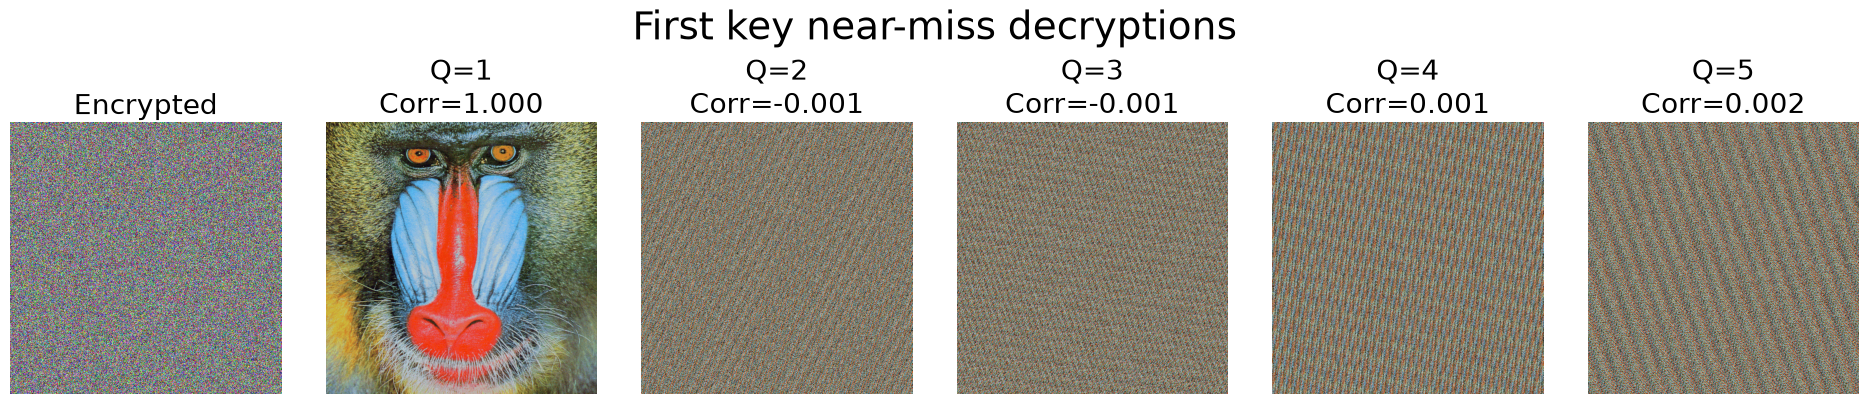

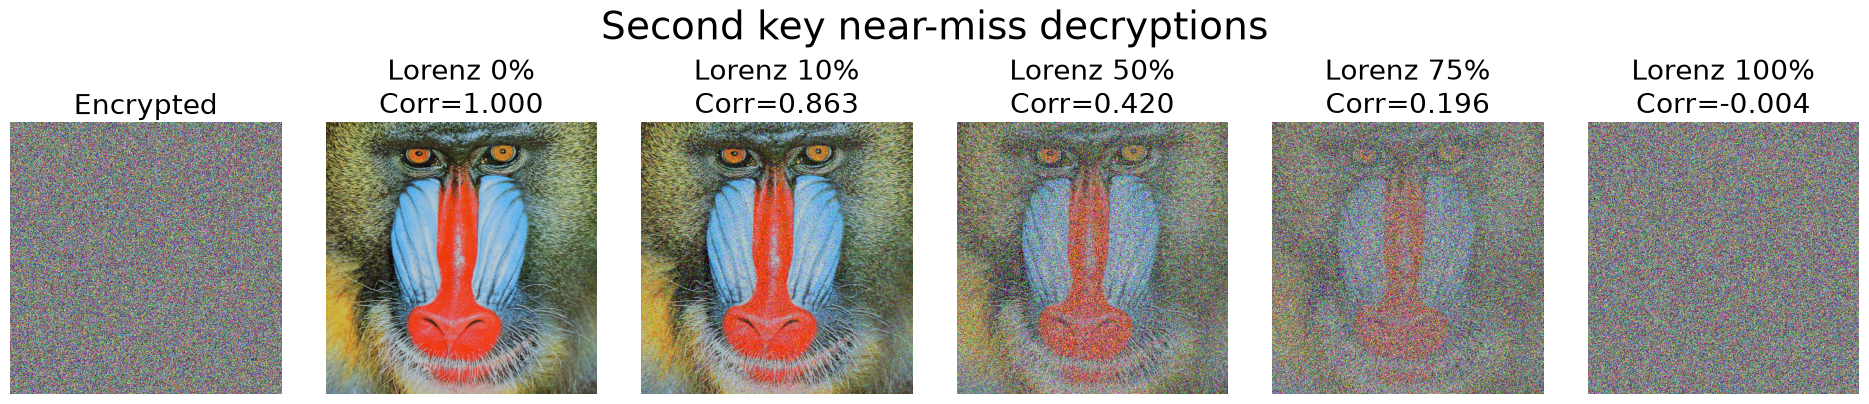

In [57]:
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.titlesize": 28,
})

encrypted = np.clip(fixed_ciphertext, 0, 255).astype(np.uint8)

#plot 5 correction
n_images = len(CATMAP_Q_TESTS) + 1
fig, axes = plt.subplots(
    1, n_images,
    figsize=(3.2 * n_images, 4.2),
    squeeze=False,
)
axes = axes.ravel()

axes[0].imshow(encrypted)
axes[0].set_title("Encrypted")
axes[0].axis("off")

for i, (q_test, image, corr) in enumerate(
    zip(CATMAP_Q_TESTS, Q_decryptions, Q_correlations),
    start=1,
):
    axes[i].imshow(np.clip(image, 0, 255).astype(np.uint8))
    axes[i].set_title(f"Q={q_test}\nCorr={corr:.3f}")
    axes[i].axis("off")

fig.suptitle("First key near-miss decryptions")
plt.tight_layout()
fig.subplots_adjust(top=fig.subplotpars.top - 0.04)
plt.show()

fig, axes = plt.subplots(
    1,
    len(IMAGE_KEY_DISTANCES) + 1,
    figsize=(3.2 * (len(IMAGE_KEY_DISTANCES) + 1), 4.2),
    squeeze=False,
)
axes = axes.ravel()

axes[0].imshow(encrypted)
axes[0].set_title("Encrypted")
axes[0].axis("off")

for i, distance in enumerate(IMAGE_KEY_DISTANCES, start=1):
    test_keys, _ = make_perturbed_key(real_keys, distance, seed=12345)

    undiffused = itm.inverseLorenzDiffuse(fixed_ciphertext, test_keys)
    decrypted = itm.InverseArnoldCatMapTransform(
        undiffused, ARNOLD_ITERATIONS, Q, P
    )

    corr = rgb_correlation(original, decrypted)

    axes[i].imshow(np.clip(decrypted, 0, 255).astype(np.uint8))
    axes[i].set_title(f"Lorenz {distance}%\nCorr={corr:.3f}")
    axes[i].axis("off")

fig.suptitle("Second key near-miss decryptions")
plt.tight_layout()
fig.subplots_adjust(top=fig.subplotpars.top - 0.04)
plt.show()